In [13]:
from square import *
import qibo
from qibo import Circuit, gates, set_backend
import time


set_backend("qibojit", platform="cuda")

[Qibo 0.3.5|INFO|2026-10-13 09:23:26]: Using qibojit (numba) backend on /CPU:0


# Ripple carry adder

In [14]:
n_qubits = list(range(2,20))
cnots = []
toffolis = []
depths = []
total = []
xs = []
for m in n_qubits:
    sq, allocs = Square(m, method='ripple_input_carry', input_swaps = False) # Select method 
    
    stats={
        'input_qubits' : m,
        'total_qubits' : sq.nqubits,
        'total_gates' : sq.ngates,
        'depth' : sq.depth,
    }
    common_gates = sq.gate_names.most_common()
    for g, n in common_gates:
        stats = stats | {g : n}
    print('===================')
    for stat in stats.keys():
        print(f'{stat} : {stats[stat]}')
    cnots.append(stats['cx'])
    toffolis.append(stats['ccx'])
    depths.append(stats['depth'])
    total.append(stats['total_gates'])
    xs.append(stats['x'])


input_qubits : 2
total_qubits : 9
total_gates : 90
depth : 58
cx : 48
x : 25
ccx : 17
input_qubits : 3
total_qubits : 13
total_gates : 187
depth : 112
cx : 103
x : 51
ccx : 33
input_qubits : 4
total_qubits : 17
total_gates : 310
depth : 177
cx : 172
x : 85
ccx : 53
input_qubits : 5
total_qubits : 21
total_gates : 459
depth : 255
cx : 255
x : 127
ccx : 77
input_qubits : 6
total_qubits : 25
total_gates : 634
depth : 345
cx : 352
x : 177
ccx : 105
input_qubits : 7
total_qubits : 29
total_gates : 835
depth : 447
cx : 463
x : 235
ccx : 137
input_qubits : 8
total_qubits : 33
total_gates : 1062
depth : 561
cx : 588
x : 301
ccx : 173
input_qubits : 9
total_qubits : 37
total_gates : 1315
depth : 687
cx : 727
x : 375
ccx : 213
input_qubits : 10
total_qubits : 41
total_gates : 1594
depth : 825
cx : 880
x : 457
ccx : 257
input_qubits : 11
total_qubits : 45
total_gates : 1899
depth : 975
cx : 1047
x : 547
ccx : 305
input_qubits : 12
total_qubits : 49
total_gates : 2230
depth : 1137
cx : 1228
x : 64

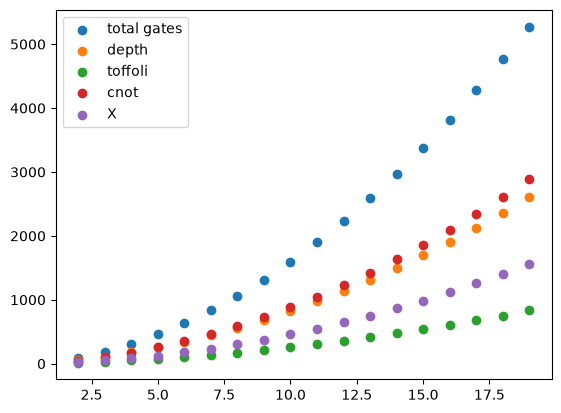

In [15]:
import matplotlib.pyplot as plt

plt.scatter(n_qubits, total, label = 'total gates')
plt.scatter(n_qubits, depths, label = 'depth')
plt.scatter(n_qubits, toffolis, label = 'toffoli')
plt.scatter(n_qubits, cnots, label = 'cnot')
plt.scatter(n_qubits, xs, label = 'X')

plt.legend()


In [16]:
from scipy.optimize import curve_fit

def poly(x, a0, a1, a2):
    y = a0 + a1*x + a2*x**2
    return y

In [17]:
data = {'total_gates': total,
        'depth': depths,
        'toffoli': toffolis,
        'cnot': cnots,
        'x': xs
        }

for stat in data.keys():
        param, _ = curve_fit(poly, n_qubits[1:], data[stat][1:])
        print(f'======{stat}======')
        for i in range(len(param)):
                print(f'a{i} : {param[i]}')

======total_gates======
a0 : -25.999999999999993
a1 : 32.0
a2 : 13.0
======depth======
a0 : -14.22497411607018
a1 : 23.86687304917185
a2 : 6.005159959367385
======toffoli======
a0 : -3.0000000000000275
a1 : 6.000000000000008
a2 : 1.9999999999999996
======cnot======
a0 : -20.00000000000006
a1 : 20.000000000000018
a2 : 6.999999999999999
======x======
a0 : -3.000000000000035
a1 : 6.000000000000011
a2 : 3.9999999999999996


# Approx. QFT scaling

In [18]:
import numpy as np
from tqdm import tqdm

m_max = 14
m_range = list(range(2, m_max))

stats = ['total_gates', 'depth', 'toffoli', 'cnot', 'x', 'h', 'cu1']
values = {key : np.zeros((len(m_range), 2*m_max)) for key in stats}


for i_m in tqdm(range(len(m_range))):
    i_d = 0
    for delta in range(1, 2*m_range[i_m]+1):
        sq, allocs = Square(i_m+2, method='aqft', delta = delta, parallel = False,input_swaps = False)

        values['total_gates'][i_m, i_d] = sq.ngates
        values['depth'][i_m, i_d] = sq.depth
        values['toffoli'][i_m, i_d] = sq.gate_names['ccx']
        values['cnot'][i_m, i_d] = sq.gate_names['cx']
        values['x'][i_m, i_d] = sq.gate_names['x']
        values['h'][i_m, i_d] = sq.gate_names['h']
        values['cu1'][i_m, i_d] = sq.gate_names['cu1']
        i_d += 1








100%|██████████| 12/12 [00:12<00:00,  1.02s/it]


In [19]:
from scipy.optimize import curve_fit

def poly(x, a0, a1, a2):
    y = a0 + a1*x + a2*x**2
    return y

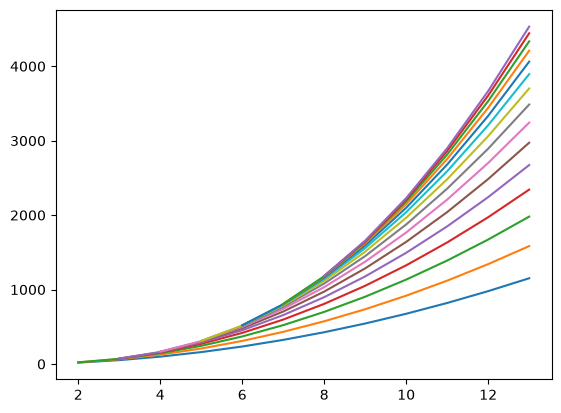

In [20]:
import matplotlib.pyplot as plt

stat = 'cu1'

b0 = np.zeros(2*m_max); b1 = np.zeros(2*m_max); b2 = np.zeros(2*m_max)

for i_d in range(1,2*(m_max-1)-10):
    delta = i_d + 1
    if delta <=4:
        min_m = 2
    else :
        min_m = np.ceil(delta/2)
    #print(min_m)
    min_i_m = m_range.index(int(min_m))
    param, _ = curve_fit(poly, m_range[min_i_m:], values[stat][min_i_m:,i_d])
    b0[i_d] = param[0]
    b1[i_d] = param[1]
    b2[i_d] = param[2]
    plt.plot(m_range[min_i_m:], values[stat][min_i_m:,i_d], label = f'd={delta}')

#plt.legend()
    

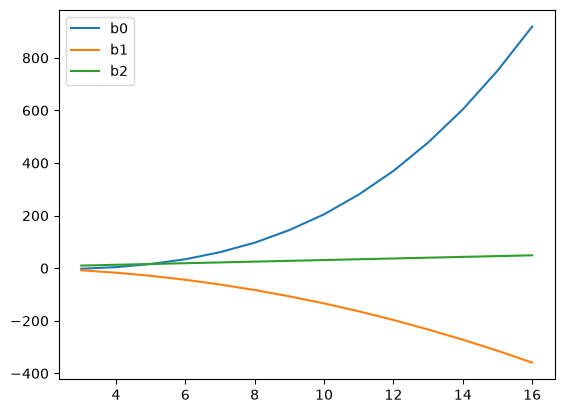

In [21]:
deltas = [s+1 for s in range(0,2*(m_max))]
smax = 16
smin = 2
deltas = deltas[smin:smax]
plt.plot(deltas, b0[smin:smax], label = 'b0') 
plt.plot(deltas, b1[smin:smax], label = 'b1') 
plt.plot(deltas, b2[smin:smax], label = 'b2') 
plt.legend()

In [22]:
print(b0[smin:smax])
print(b1[smin:smax])
print(b2[smin:smax])
deltas


[ -2.   4.  16.  34.  61.  97. 145. 205. 280. 370. 478. 604. 751. 919.]
[  -8.  -17.  -29.  -44.  -62.  -83. -107. -134. -164. -197. -233. -272.
 -314. -359.]
[10. 13. 16. 19. 22. 25. 28. 31. 34. 37. 40. 43. 46. 49.]


[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

In [23]:
param, _ = curve_fit(poly, deltas, b2[smin:smax])
print(param)

[ 1.00000000e+00  3.00000000e+00 -1.33226765e-15]


# Time elapsed by m (ran in colab)

Exhaustive verification of the primitive for the different sub/add subroutines. For each input length $m$, the circuit is built and executed for all $2^m$ possible inputs. The wallclock time of 1 shot is averaged over all inputs and its mean and std. is stored; then, the result is verified repeating the measurement for ``nshots``, computing the average error over all inputs.
The result is the scaling of both the average simulation time and error over the ize of the length of the input integer.

qibojit GPU T4

In [ ]:
from square import *
from qibo import gates
import time
import numpy as np

times = []
times_sd = []
error = []
nshots = 1000


for m in range(2, 7):
  n = 2 * m
  num_qubits = 2 * n + 1
  m_times = []
  avg_sr = 0
  for x in range(2**m):
      #sq, (R, F, Z) = Square(m, method='aqft', delta = 2*m, parallel = True, input_swaps = False)
      sq, (R, F, Z) = Square(m, method='ripple_input_carry', input_swaps = False)
      circ = initialize_square(x, m, allocs = (R, F, Z), direct=True)
      circ.add(sq.on_qubits(*range(num_qubits)))
      circ.add(gates.M(*range(num_qubits)))
      start = time.time()
      res_time = circ(nshots=1)
      end = time.time()
      m_times.append(end - start)

      res = circ(nshots=nshots)
      samples = res.samples()
      square_bits = [samp[R[0]:R[n-1]+1] for samp in samples]
      square_value =[sum(bit << i for i, bit in enumerate(sqbits)) for sqbits in square_bits]
      prob = sum(int(sq_val) == int(x**2) for sq_val in square_value)/nshots
      avg_sr += prob/2**m

  error.append(avg_sr)
  times.append(np.mean(m_times))
  times_sd.append(np.std(m_times))
  print(f'm={m} | Avg. time: {np.mean(m_times)} | Std. time: {np.std(m_times)} | Error: {1-avg_sr}')


Ripple with input carry - Output:<br>

m=2 | Avg. time: 0.012710869312286377 | Std. time: 0.0017087886893896406 | Error: 0.0<br>
m=3 | Avg. time: 0.02506929636001587 | Std. time: 0.004008865300277052 | Error: 0.0<br>
m=4 | Avg. time: 0.04393364489078522 | Std. time: 0.005338563101590237 | Error: 0.0<br>
m=5 | Avg. time: 0.1559438481926918 | Std. time: 0.011448955007401344 | Error: 0.0<br>
m=6 | Avg. time: 2.1436324678361416 | Std. time: 0.0444001691786249 | Error: 0.0<br>

In [51]:
mrange = list(range(2, 7))
ric = [0.012710869312286377, 0.02506929636001587, 0.04393364489078522, 0.1559438481926918, 2.1436324678361416]
ric_sd = [0.0017087886893896406, 0.004008865300277052, 0.005338563101590237, 0.011448955007401344, 0.0444001691786249]


Ripple without input carry - Output: <br>

m=2 | Avg. time: 0.011722564697265625 | Std. time: 0.002439719467028801 | Error: 0.0<br>
m=3 | Avg. time: 0.01834017038345337 | Std. time: 0.00039122579601081036 | Error: 0.0<br>
m=4 | Avg. time: 0.03677359223365784 | Std. time: 0.00901347873218011 | Error: 0.0<br>
m=5 | Avg. time: 0.10623326152563095 | Std. time: 0.007834838907979187 | Error: 0.0<br>
m=6 | Avg. time: 1.3799843415617943 | Std. time: 0.03771321874457498 | Error: 0.0<br>

In [83]:
rnic = [0.011722564697265625, 0.01834017038345337, 0.03677359223365784, 0.10623326152563095, 1.3799843415617943]
rnic_sd = [0.002439719467028801, 0.00039122579601081036, 0.00901347873218011, 0.007834838907979187, 0.03771321874457498]

Exact QFT - Output: <br>

m=2 | Avg. time: 0.017193734645843506 | Std. time: 0.002679372359699595 | Error: 0.0<br>
m=3 | Avg. time: 0.03460872173309326 | Std. time: 0.008218648330181105 | Error: 0.0<br>
m=4 | Avg. time: 0.053032368421554565 | Std. time: 0.003996912275606175 | Error: 0.0<br>
m=5 | Avg. time: 0.20455752313137054 | Std. time: 0.06376286375915521 | Error: 0.0<br>
m=6 | Avg. time: 1.899760477244854 | Std. time: 0.028128447746998138 | Error: 0.0<br>



In [86]:
qft = [0.017193734645843506, 0.03460872173309326, 0.053032368421554565, 0.20455752313137054, 1.899760477244854]
qft_sd = [0.002679372359699595, 0.008218648330181105, 0.003996912275606175, 0.06376286375915521, 0.028128447746998138]


Exact QFT (parallel) - Output: <br>

m=2 | Avg. time: 0.013172805309295654 | Std. time: 0.003075646431400176 | Error: 0.0<br>
m=3 | Avg. time: 0.029326021671295166 | Std. time: 0.001822202998797523 | Error: 0.0<br>
m=4 | Avg. time: 0.059759244322776794 | Std. time: 0.009176431131437332 | Error: 0.0<br>
m=5 | Avg. time: 0.16946785897016525 | Std. time: 0.01546920409029163 | Error: 0.0<br>
m=6 | Avg. time: 1.8953352309763432 | Std. time: 0.025227622927496564 | Error: 0.0<br>

In [85]:
qftp = [0.013172805309295654, 0.029326021671295166, 0.059759244322776794, 0.16946785897016525, 1.8953352309763432]
qftp_sd = [0.003075646431400176, 0.001822202998797523, 0.009176431131437332, 0.01546920409029163, 0.025227622927496564]

Approximate QFT (delta = 4) - Output: <br>

m=2 | Avg. time: 0.013024747371673584 | Std. time: 0.002636179395980268 | Error: 0.0<br>
m=3 | Avg. time: 0.02690446376800537 | Std. time: 0.002525119659321477 | Error: 0.02212500000000006<br>
m=4 | Avg. time: 0.054590508341789246 | Std. time: 0.011878407160443418 | Error: 0.078125<br>
m=5 | Avg. time: 0.151732936501503 | Std. time: 0.017978861218225888 | Error: 0.15768749999999987<br>
m=6 | Avg. time: 1.6810606345534325 | Std. time: 0.046144638648402764 | Error: 0.24576562499999988<br>


In [88]:
aqft4 = [0.013024747371673584, 0.02690446376800537, 0.054590508341789246, 0.151732936501503, 1.6810606345534325]
aqft4_sd = [0.002636179395980268, 0.002525119659321477, 0.011878407160443418, 0.017978861218225888, 0.046144638648402764]

Approximate QFT (parallel, delta = 4) - Output: <br>

m=2 | Avg. time: 0.012030065059661865 | Std. time: 0.0011443831442687724 | Error: 0.0<br>
m=3 | Avg. time: 0.0262012779712677 | Std. time: 0.0013623933906458997 | Error: 0.024124999999999952<br>
m=4 | Avg. time: 0.054295897483825684 | Std. time: 0.011187476616757092 | Error: 0.07906250000000015<br>
m=5 | Avg. time: 0.14849626272916794 | Std. time: 0.010664376359608558 | Error: 0.15465624999999983<br>
m=6 | Avg. time: 1.6786973848938942 | Std. time: 0.041356516583824506 | Error: 0.24782812500000007<br>

In [92]:
aqftp4 = [0.012030065059661865, 0.0262012779712677, 0.054295897483825684, 0.14849626272916794, 1.6786973848938942]
aqftp4_sd = [0.0011443831442687724, 0.0013623933906458997, 0.011187476616757092, 0.010664376359608558,0.041356516583824506]

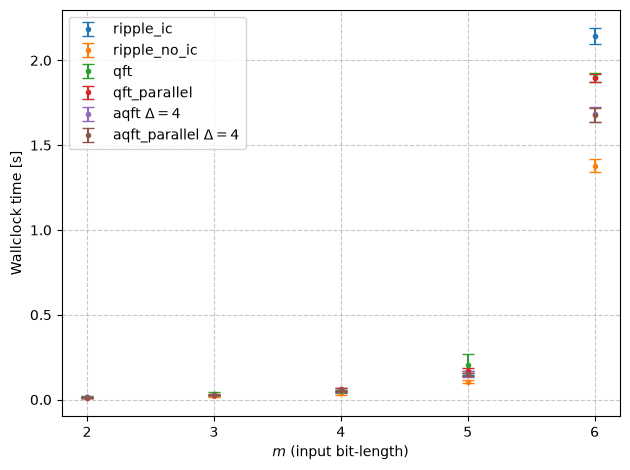

In [93]:
plt.errorbar(mrange, ric, yerr=ric_sd, markersize = 6, capsize=4, fmt=".", label = 'ripple_ic')
plt.errorbar(mrange, rnic, yerr=rnic_sd, markersize = 6, capsize=4, fmt=".", label = 'ripple_no_ic')
plt.errorbar(mrange, qft, yerr=qft_sd, markersize = 6, capsize=4, fmt=".", label = 'qft')
plt.errorbar(mrange, qftp, yerr=qftp_sd, markersize = 6, capsize=4, fmt=".", label = 'qft_parallel')
plt.errorbar(mrange, aqft4, yerr=aqft4_sd, markersize = 6, capsize=4, fmt=".", label = r'aqft $\Delta=4$')
plt.errorbar(mrange, aqftp4, yerr=aqftp4_sd, markersize = 6, capsize=4, fmt=".", label = r'aqft_parallel $\Delta=4$')

plt.xticks(mrange)
plt.xlabel(r'$m$ (input bit-length)')
plt.ylabel(r'Wallclock time [s]')
#plt.yscale('log')
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()